# 10 — Visual Representations for Robot Policies

Modern robot learning architectures rely on visual
representations that preserve information about objects,
spatial relationships, and possible interactions.

In previous notebooks, our visual encoder compressed
an entire image into a single feature vector:

$$
I \rightarrow v \in \mathbb{R}^{d}
$$

This representation is compact, but spatial information
must be encoded implicitly in the vector.

An alternative is to preserve a grid of visual features:

$$
I \rightarrow F \in \mathbb{R}^{C \times H' \times W'}
$$

We can flatten this grid into visual tokens:

$$
F \rightarrow V \in \mathbb{R}^{N \times C}
$$

where $N=H'W'$.

These tokens can be processed by attention mechanisms,
allowing action queries to access different image regions.

We begin by inspecting the feature maps of a CNN.

## Dataset Setup

We use the LeRobot PushT dataset with an 80/20 episode-level
train/validation split.

Each sample contains:
- One RGB image (3 × 96 × 96)
- The current 2D robot state
- A chunk of 8 future 2D actions

States and actions are normalized using statistics computed
exclusively from the training episodes.

In [13]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from lerobot.datasets.lerobot_dataset import LeRobotDataset

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

H = 8
BATCH_SIZE = 64

dataset = LeRobotDataset("lerobot/pusht")

# Episode-level split
rng = np.random.default_rng(42)
episode_ids = rng.permutation(dataset.meta.total_episodes)

n_train = int(0.8 * len(episode_ids))
train_ids = episode_ids[:n_train]
val_ids = episode_ids[n_train:]

# Episode boundaries
episodes = dataset.meta.episodes

def episode_range(ep_id):
    info = episodes[int(ep_id)]
    return (
        int(info["dataset_from_index"]),
        int(info["dataset_to_index"]),
    )

# Cache states and actions, not images
all_states = torch.stack([
    dataset[i]["observation.state"]
    for i in range(len(dataset))
])

all_actions = torch.stack([
    dataset[i]["action"]
    for i in range(len(dataset))
])

# Training-only normalization
train_indices = [
    i
    for ep in train_ids
    for i in range(*episode_range(ep))
]

state_mean = all_states[train_indices].mean(0).to(device)
state_std = all_states[train_indices].std(0).clamp_min(1e-6).to(device)

action_mean = all_actions[train_indices].mean(0).to(device)
action_std = all_actions[train_indices].std(0).clamp_min(1e-6).to(device)


class PushTChunkDataset(Dataset):
    def __init__(self, dataset, episode_ids, states, actions, horizon=8):
        self.dataset = dataset
        self.states = states
        self.actions = actions
        self.horizon = horizon

        self.indices = [
            t
            for ep in episode_ids
            for start, end in [episode_range(ep)]
            for t in range(start, end - horizon + 1)
        ]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        t = self.indices[idx]

        return {
            "image": self.dataset[t]["observation.image"],
            "state": self.states[t],
            "actions": self.actions[t:t + self.horizon],
        }


train_dataset = PushTChunkDataset(
    dataset, train_ids, all_states, all_actions, H
)

val_dataset = PushTChunkDataset(
    dataset, val_ids, all_states, all_actions, H
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)


def prepare_chunk_batch(batch):
    images = batch["image"].to(device)
    states = batch["state"].to(device)
    actions = batch["actions"].to(device)

    states = (states - state_mean) / state_std
    actions = (actions - action_mean) / action_std

    return images, states, actions


# Sanity check
batch = next(iter(train_loader))
images, states, actions = prepare_chunk_batch(batch)

print("Device:", device)
print("Train chunks:", len(train_dataset))
print("Validation chunks:", len(val_dataset))
print("Images:", images.shape)
print("States:", states.shape)
print("Actions:", actions.shape)

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1164.52it/s]


Device: mps
Train chunks: 19571
Validation chunks: 4637
Images: torch.Size([64, 3, 96, 96])
States: torch.Size([64, 2])
Actions: torch.Size([64, 8, 2])


In [15]:
class SpatialVisualEncoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 5, stride=2, padding=2),
            nn.ReLU(),

            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.ReLU(),
        )

    def forward(self, images):
        return self.cnn(images)


spatial_encoder = SpatialVisualEncoder().to(device)


dataset = LeRobotDataset("lerobot/pusht")

rng = np.random.default_rng(42)
n_episodes = dataset.meta.total_episodes
episode_ids = rng.permutation(n_episodes)

n_train_episodes = int(0.8 * n_episodes)

train_episode_ids = episode_ids[:n_train_episodes]
val_episode_ids = episode_ids[n_train_episodes:]

H = 8
val_chunk_dataset = PushTChunkDataset(
    dataset, val_episode_ids, all_states, all_actions, H
)

sample = val_chunk_dataset[100]
image = sample["image"].unsqueeze(0).to(device)

with torch.no_grad():
    feature_map = spatial_encoder(image)

print("Input image:", image.shape)
print("Feature map:", feature_map.shape)

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1068.88it/s]

Input image: torch.Size([1, 3, 96, 96])
Feature map: torch.Size([1, 128, 12, 12])


In [6]:
B, C, Hf, Wf = feature_map.shape

visual_tokens = feature_map.flatten(2).transpose(1, 2)

print("Visual tokens:", visual_tokens.shape)
print("Number of tokens:", Hf * Wf)
print("Embedding dimension:", C)

Visual tokens: torch.Size([1, 144, 128])
Number of tokens: 144
Embedding dimension: 128


### 1.1 Spatial Positional Encoding and Cross-Attention

A CNN produces a spatial grid of visual features.

After flattening, the grid becomes a sequence of tokens.
To preserve spatial structure, we add a positional encoding:

$$
\tilde{v}_{i,j} = v_{i,j} + p_{i,j}
$$

We then introduce learned action queries that attend to
the visual tokens through cross-attention:

$$
Y = \operatorname{Attention}(Q,K,V)
$$

where:

- $Q$ comes from learned action queries.
- $K$ and $V$ come from visual tokens.
- $Y$ contains visual information selected for each query.

We will inspect the attention weights to understand how
different image regions contribute to each action query.

In [16]:
class SpatialCrossAttention(nn.Module):
    def __init__(self, grid_size=12, dim=128, num_queries=8):
        super().__init__()

        self.pos_embedding = nn.Parameter(
            torch.randn(1, grid_size * grid_size, dim) * 0.02
        )

        self.action_queries = nn.Parameter(
            torch.randn(1, num_queries, dim) * 0.02
        )

        self.cross_attention = nn.MultiheadAttention(
            embed_dim=dim,
            num_heads=4,
            batch_first=True,
        )

    def forward(self, visual_tokens):
        B = visual_tokens.shape[0]

        memory = visual_tokens + self.pos_embedding

        queries = self.action_queries.expand(B, -1, -1)

        output, attention_weights = self.cross_attention(
            query=queries,
            key=memory,
            value=memory,
            need_weights=True,
            average_attn_weights=False,
        )

        return output, attention_weights


spatial_attention = SpatialCrossAttention().to(device)

with torch.no_grad():
    attended_tokens, attention_weights = spatial_attention(
        visual_tokens
    )

print("Action tokens:", attended_tokens.shape)
print("Attention weights:", attention_weights.shape)

Action tokens: torch.Size([1, 8, 128])
Attention weights: torch.Size([1, 4, 8, 144])


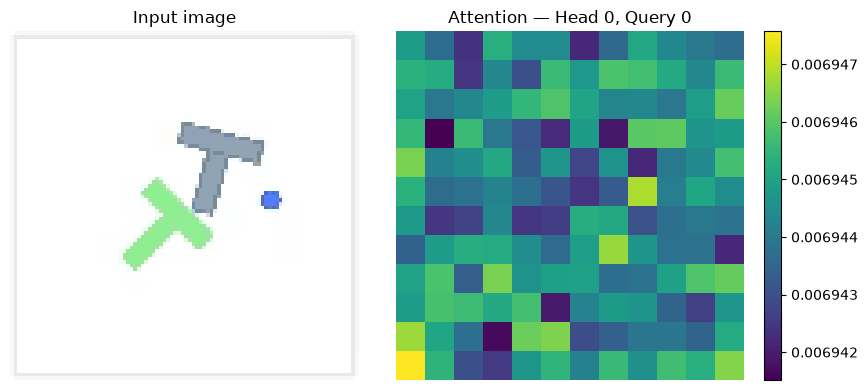

In [17]:
# First image, first attention head, first action query
attention_map = (
    attention_weights[0, 0, 0]
    .reshape(12, 12)
    .detach()
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(
    image[0].permute(1, 2, 0).cpu()
)
axes[0].set_title("Input image")
axes[0].axis("off")

im = axes[1].imshow(
    attention_map,
    cmap="viridis",
    interpolation="nearest",
)
axes[1].set_title("Attention — Head 0, Query 0")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

### 1.2 Spatial Action Decoder

We build a simple visuomotor policy that preserves spatial
image features.

Instead of compressing the image into a single vector,
the CNN produces a grid of visual tokens.

Learned action queries attend to these tokens and predict
future robot actions.

The architecture is:

$$
I_t \rightarrow V_t \rightarrow
\operatorname{CrossAttention}(Q,V_t)
\rightarrow \hat A_t
$$

We also provide the normalized robot state to the action
queries.

This architecture illustrates a key idea used in modern
robot policies: action representations can attend directly
to spatial visual features.

In [18]:
class SpatialActionPolicy(nn.Module):
    def __init__(self, horizon=8, dim=128):
        super().__init__()

        self.visual_encoder = SpatialVisualEncoder()

        self.cross_attention = SpatialCrossAttention(
            grid_size=12,
            dim=dim,
            num_queries=horizon,
        )

        self.state_projection = nn.Linear(2, dim)

        self.action_head = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, 2),
        )

    def forward(self, images, states):
        feature_map = self.visual_encoder(images)

        visual_tokens = feature_map.flatten(2).transpose(1, 2)

        action_tokens, attention_weights = self.cross_attention(
            visual_tokens
        )

        state_features = self.state_projection(states).unsqueeze(1)

        action_tokens = action_tokens + state_features

        predicted_actions = self.action_head(action_tokens)

        return predicted_actions, attention_weights

In [20]:
spatial_policy = SpatialActionPolicy(horizon=H).to(device)

batch = next(iter(train_loader))
images, states, actions = prepare_chunk_batch(batch)

with torch.no_grad():
    predicted_actions, attention_weights = spatial_policy(
        images, states
    )

print("Predicted actions:", predicted_actions.shape)
print("Attention weights:", attention_weights.shape)

print(
    "Parameters:",
    sum(p.numel() for p in spatial_policy.parameters())
)

Predicted actions: torch.Size([64, 8, 2])
Attention weights: torch.Size([64, 4, 8, 144])
Parameters: 181186


### 1.3 Training a Spatial Attention Policy

We train a visuomotor policy that predicts an action chunk
from spatial visual tokens and the current robot state.

Unlike a global visual embedding, the model preserves a
12 × 12 grid of image features.

Each of the eight learned action queries attends to the
144 visual tokens.

The training objective is:

$$
\mathcal{L} =
\frac{1}{BHD}
\sum_{b,h,d}
(\hat{a}_{b,h,d} - a_{b,h,d})^2
$$

After training, we will inspect the attention maps and
compare them with those of the untrained model.

In [21]:
spatial_policy = SpatialActionPolicy(horizon=H).to(device)

optimizer = torch.optim.Adam(
    spatial_policy.parameters(),
    lr=1e-3,
)

num_epochs = 5

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    spatial_policy.train()
    train_total = 0.0

    for batch in train_loader:
        images, states, actions = prepare_chunk_batch(batch)

        predictions, _ = spatial_policy(images, states)
        loss = F.mse_loss(predictions, actions)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total += loss.item() * len(images)

    train_loss = train_total / len(train_dataset)
    train_losses.append(train_loss)

    spatial_policy.eval()
    val_total = 0.0

    with torch.no_grad():
        for batch in val_loader:
            images, states, actions = prepare_chunk_batch(batch)

            predictions, _ = spatial_policy(images, states)
            val_total += (
                F.mse_loss(predictions, actions).item()
                * len(images)
            )

    val_loss = val_total / len(val_dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

Epoch 1/5 | Train: 0.2371 | Val: 0.1952
Epoch 2/5 | Train: 0.2116 | Val: 0.1913
Epoch 3/5 | Train: 0.2103 | Val: 0.1904
Epoch 4/5 | Train: 0.2043 | Val: 0.1772
Epoch 5/5 | Train: 0.1717 | Val: 0.1522


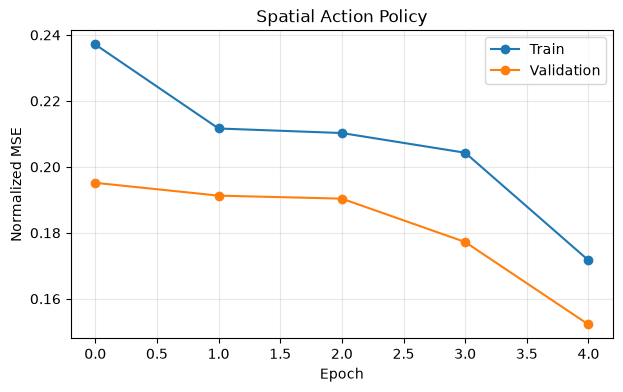

In [22]:
plt.figure(figsize=(7, 4))

plt.plot(train_losses, marker="o", label="Train")
plt.plot(val_losses, marker="o", label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("Spatial Action Policy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 1.4 Inspecting Learned Spatial Attention

After training, we visualize the attention distribution
of an action query over the 12 × 12 visual token grid.

A trained model may assign different attention weights
to different image regions.

However, attention weights are not necessarily explanations
of the policy's decisions.

We inspect them as an architectural diagnostic, not as
proof that the model understands objects or contacts.

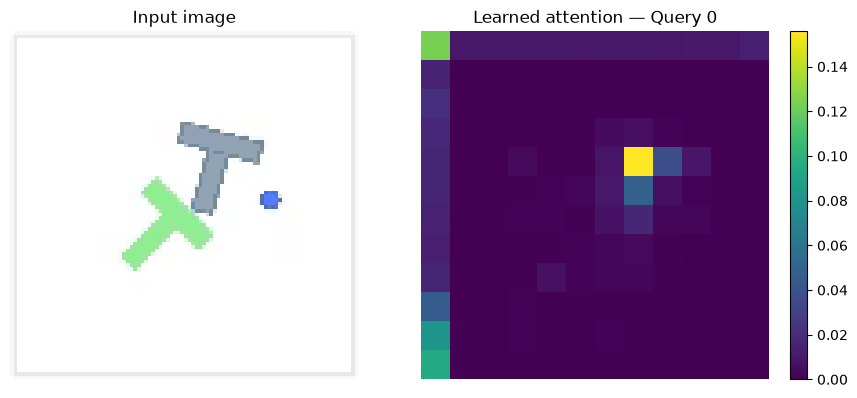

Attention min: 0.00011388173
Attention max: 0.15583478
Uniform baseline: 0.006944444444444444


In [23]:
spatial_policy.eval()

sample = val_dataset[100]

image = sample["image"].unsqueeze(0).to(device)

state = sample["state"].unsqueeze(0).to(device)
state = (state - state_mean) / state_std

with torch.no_grad():
    predicted_chunk, attention_weights = spatial_policy(
        image, state
    )

# First attention head, first action query
attention_map = (
    attention_weights[0, 0, 0]
    .reshape(12, 12)
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(image[0].permute(1, 2, 0).cpu())
axes[0].set_title("Input image")
axes[0].axis("off")

im = axes[1].imshow(
    attention_map,
    cmap="viridis",
    vmin=0,
)

axes[1].set_title("Learned attention — Query 0")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

print("Attention min:", attention_map.min())
print("Attention max:", attention_map.max())
print("Uniform baseline:", 1 / 144)

## 2. Vision Transformers

A Vision Transformer (ViT) represents an image as a
sequence of patch embeddings.

For an image of size $96 \times 96$ and patch size $16$:

$$
N = \frac{96}{16}\times\frac{96}{16}=36
$$

Each image patch is projected into a learned embedding.

Positional embeddings are added to preserve spatial
information, and Transformer self-attention allows
different patches to exchange information.

Unlike the previous CNN encoder, the Transformer explicitly
models interactions between visual tokens.

In [24]:
class PatchEmbedding(nn.Module):
    def __init__(self, patch_size=16, embed_dim=128):
        super().__init__()

        self.projection = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size,
        )

    def forward(self, images):
        patches = self.projection(images)
        return patches.flatten(2).transpose(1, 2)


patch_embedding = PatchEmbedding().to(device)

batch = next(iter(val_loader))
images, states, actions = prepare_chunk_batch(batch)

with torch.no_grad():
    patch_tokens = patch_embedding(images)

print("Images:", images.shape)
print("Patch tokens:", patch_tokens.shape)

Images: torch.Size([64, 3, 96, 96])
Patch tokens: torch.Size([64, 36, 128])


### 2.1 Vision Transformer Encoder

A Vision Transformer processes image patch embeddings
using self-attention.

We first add positional embeddings:

$$
X = \operatorname{PatchEmbed}(I) + P
$$

Then, self-attention allows each visual token to
exchange information with all other tokens:

$$
X' = \operatorname{TransformerEncoder}(X)
$$

Unlike cross-attention, where action queries attend
to image features, self-attention uses visual tokens
as queries, keys, and values.

We inspect the attention matrix before training.

In [25]:
class MiniViT(nn.Module):
    def __init__(self, embed_dim=128, num_patches=36):
        super().__init__()

        self.patch_embedding = PatchEmbedding(
            patch_size=16,
            embed_dim=embed_dim,
        )

        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_patches, embed_dim) * 0.02
        )

        self.norm1 = nn.LayerNorm(embed_dim)

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=4,
            batch_first=True,
        )

        self.norm2 = nn.LayerNorm(embed_dim)

        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, 256),
            nn.GELU(),
            nn.Linear(256, embed_dim),
        )

    def forward(self, images):
        x = self.patch_embedding(images)
        x = x + self.pos_embedding

        # Self-attention with residual connection
        y, weights = self.attention(
            x, x, x,
            need_weights=True,
            average_attn_weights=False,
        )

        x = self.norm1(x + y)

        # Feed-forward with residual connection
        x = self.norm2(x + self.mlp(x))

        return x, weights


vit = MiniViT().to(device)

vit.eval()

with torch.no_grad():
    visual_features, attention_weights = vit(images[:1])

print("Visual features:", visual_features.shape)
print("Attention weights:", attention_weights.shape)

Visual features: torch.Size([1, 36, 128])
Attention weights: torch.Size([1, 4, 36, 36])


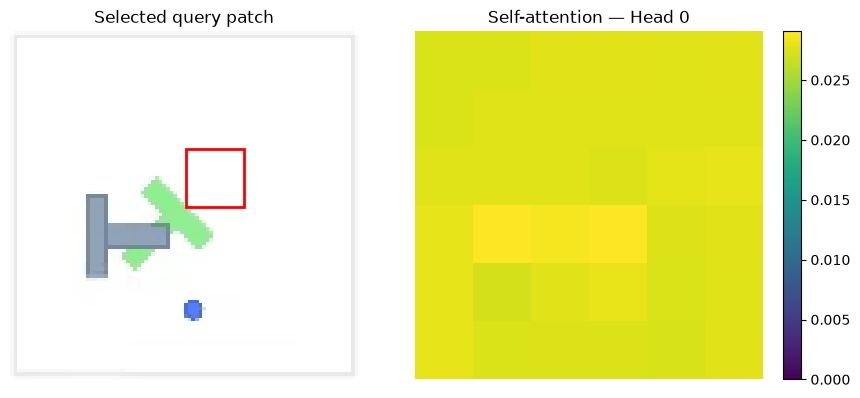

Attention min: 0.027247341
Attention max: 0.029086197
Uniform baseline: 0.027777777777777776


In [26]:
# Patch at row 2, column 3 in the 6x6 grid
query_row, query_col = 2, 3
query_idx = query_row * 6 + query_col

attention_map = (
    attention_weights[0, 0, query_idx]
    .reshape(6, 6)
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(
    images[0].permute(1, 2, 0).cpu()
)

# Highlight the selected query patch
from matplotlib.patches import Rectangle

axes[0].add_patch(
    Rectangle(
        (query_col * 16, query_row * 16),
        16, 16,
        fill=False,
        edgecolor="red",
        linewidth=2,
    )
)

axes[0].set_title("Selected query patch")
axes[0].axis("off")

im = axes[1].imshow(
    attention_map,
    cmap="viridis",
    vmin=0,
)

axes[1].set_title("Self-attention — Head 0")
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

print("Attention min:", attention_map.min())
print("Attention max:", attention_map.max())
print("Uniform baseline:", 1 / 36)

In [27]:
# permutation equivariance in self-attention

attention = nn.MultiheadAttention(
    embed_dim=128,
    num_heads=4,
    batch_first=True,
).to(device)

attention.eval()

x = torch.randn(1, 36, 128, device=device)
permutation = torch.randperm(36, device=device)

with torch.no_grad():
    y, _ = attention(x, x, x)

    x_permuted = x[:, permutation]

    y_permuted, _ = attention(
        x_permuted, x_permuted, x_permuted
    )

    # Compare permuted outputs
    error = (
        y_permuted - y[:, permutation]
    ).abs().max()

print("Maximum difference:", error.item())

Maximum difference: 1.1920928955078125e-07


## 3. From Visual Tokens to Multimodal Tokens

Vision-Language Models combine information from images
and natural language.

A visual encoder produces image tokens:

$$
V \in \mathbb{R}^{N_v \times d}
$$

A text embedding layer produces language tokens:

$$
T \in \mathbb{R}^{N_t \times d}
$$

If both representations have the same embedding dimension,
we can concatenate them:

$$
X = [V;T]
$$

A multimodal Transformer can then model interactions
between visual and linguistic tokens.

This is a simplified example of multimodal fusion,
not a pretrained Vision-Language Model.

In [28]:
vocabulary = {
    "<pad>": 0,
    "push": 1,
    "the": 2,
    "block": 3,
    "to": 4,
    "target": 5,
}

instruction = "push the block to the target"

token_ids = torch.tensor(
    [[vocabulary[word] for word in instruction.split()]],
    device=device,
)

text_embedding = nn.Embedding(
    num_embeddings=len(vocabulary),
    embedding_dim=128,
).to(device)

text_tokens = text_embedding(token_ids)

print("Token IDs:", token_ids)
print("Text tokens:", text_tokens.shape)

Token IDs: tensor([[1, 2, 3, 4, 2, 5]], device='mps:0')
Text tokens: torch.Size([1, 6, 128])


In [29]:
vit.eval()

with torch.no_grad():
    visual_tokens, _ = vit(images[:1])

# 36 visual tokens + 6 text tokens
multimodal_tokens = torch.cat(
    [visual_tokens, text_tokens],
    dim=1,
)

multimodal_attention = nn.MultiheadAttention(
    embed_dim=128,
    num_heads=4,
    batch_first=True,
).to(device)

multimodal_attention.eval()

with torch.no_grad():
    fused_tokens, attention_weights = multimodal_attention(
        multimodal_tokens,
        multimodal_tokens,
        multimodal_tokens,
        need_weights=True,
        average_attn_weights=False,
    )

print("Visual tokens:", visual_tokens.shape)
print("Text tokens:", text_tokens.shape)
print("Multimodal tokens:", multimodal_tokens.shape)
print("Fused tokens:", fused_tokens.shape)
print("Attention weights:", attention_weights.shape)

Visual tokens: torch.Size([1, 36, 128])
Text tokens: torch.Size([1, 6, 128])
Multimodal tokens: torch.Size([1, 42, 128])
Fused tokens: torch.Size([1, 42, 128])
Attention weights: torch.Size([1, 4, 42, 42])


### 3.1 Inspecting Text-to-Vision Attention

We inspect how a language token attends to image patches.

The multimodal sequence contains 36 visual tokens followed
by 6 language tokens.

We select the query corresponding to the word "block"
and extract its attention weights over the visual tokens.

The resulting 36 weights are reshaped into a 6 × 6 map.

Since our text embeddings and multimodal attention are
untrained, this experiment demonstrates the mechanism,
not semantic grounding.

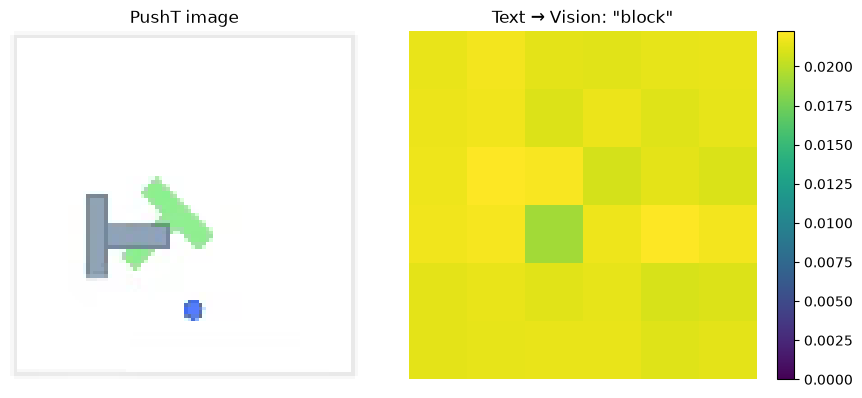

Visual attention sum: 0.77090865
Min: 0.019150693
Max: 0.022258012


In [30]:
# "push the block to the target"
words = instruction.split()
word_idx = words.index("block")

n_visual = visual_tokens.shape[1]
query_idx = n_visual + word_idx

# Head 0: text query "block" -> visual keys
text_to_vision = (
    attention_weights[0, 0, query_idx, :n_visual]
    .reshape(6, 6)
    .detach()
    .cpu()
    .numpy()
)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(images[0].permute(1, 2, 0).cpu())
axes[0].set_title("PushT image")
axes[0].axis("off")

im = axes[1].imshow(
    text_to_vision,
    cmap="viridis",
    vmin=0,
)
axes[1].set_title('Text → Vision: "block"')
axes[1].axis("off")

plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

print("Visual attention sum:", text_to_vision.sum())
print("Min:", text_to_vision.min())
print("Max:", text_to_vision.max())